# Giorno 1 — Fondamenti di Machine Learning e primo modello

> Linguaggio degli esempi: Python 3 (scikit-learn ≥ 1.4, NumPy, pandas, matplotlib). Ogni modulo segue la struttura: Spiegazione teorica → Esempi teorici di utilizzo → Esempi di codice → Esercizi.

# 1.1 Cos'è il Machine Learning

## Spiegazione teorica

**Intelligenza Artificiale, Machine Learning, Deep Learning** sono tre insiemi uno dentro l'altro:
- **Intelligenza Artificiale (AI):** tutte le tecniche che permettono a una macchina di svolgere compiti che normalmente richiedono intelligenza umana (riconoscere, decidere, tradurre…).
- **Machine Learning (ML):** la parte dell'AI in cui il computer **impara dai dati** invece di seguire regole scritte a mano dal programmatore.
- **Deep Learning (DL):** la parte del ML che usa **reti neurali con molti strati** (lo vedremo nei giorni 6–7 con TensorFlow/Keras).

**Programmazione classica vs Machine Learning**
- Programmazione classica: `regole + dati → risposte`. Il programmatore scrive le regole (`if ore >= 6: promosso`).
- Machine Learning: `dati + risposte → regole`. Diamo al computer molti esempi già risolti e lui ricava la regola da solo.

**Le parole chiave**
- **Algoritmo di apprendimento:** la *procedura* che cerca la regola nei dati (es. "prova tutte le soglie e tieni la migliore"). È la ricetta.
- **Modello:** il *risultato* dell'apprendimento: una funzione matematica che, dato un input, produce un output. È la torta uscita dal forno.
- **Parametri (o pesi):** i numeri interni al modello che vengono regolati durante l'apprendimento (es. il valore della soglia, i coefficienti di una retta).
- **Addestramento (training):** il processo in cui l'algoritmo regola i parametri in modo che il modello sbagli il meno possibile sugli esempi.
- **Inferenza / predizione:** l'uso del modello già addestrato su dati **nuovi**, mai visti prima.
- **Pattern:** una regolarità nei dati (es. "chi studia di più tende a essere promosso"). Il ML cerca pattern, non certezze: le predizioni sono **probabili**, non garantite.

**Obiettivo del ML:** automatizzare decisioni o previsioni basandosi su pattern appresi dai dati, soprattutto quando le regole sono troppe, troppo complesse o cambiano nel tempo.

## Esempi teorici di utilizzo

- **Filtro anti-spam:** impossibile scrivere a mano tutte le regole per riconoscere lo spam (e gli spammer cambiano tattica); il modello impara da migliaia di email già etichettate.
- **Stima del prezzo di una casa:** il prezzo dipende da metri quadri, zona, piano, stato… in modo intrecciato; il modello ricava il peso di ciascun fattore dalle vendite passate.
- **Rilevamento frodi sulle carte:** le frodi cambiano continuamente; un modello si può riaddestrare sui dati nuovi invece di riscrivere il codice.
- **Raccomandazioni (film, prodotti):** si scoprono gusti simili tra utenti senza che nessuno li abbia definiti.
- **Quando NON serve il ML:** calcolare l'IVA, convertire valute, validare un codice fiscale. Se la regola è nota, semplice e stabile, una funzione scritta a mano è più semplice, veloce e affidabile.

## Esempi di codice

### Base
Cosa mostra: la programmazione classica, dove la regola la decide il programmatore.

In [161]:
# La regola è scritta "a mano": la soglia 6 l'ha scelta il programmatore
def promosso(ore_studio):
    return ore_studio >= 6          # nessun dato è stato usato per decidere il 6

print(promosso(4))                  # False
print(promosso(8))                  # True

False
True


- La soglia è fissa e decisa da una persona, non dai dati.
- Se la realtà cambia (es. esame più difficile) bisogna riscrivere il codice.
- Funziona bene solo se conosciamo già la regola giusta.

### Intermedio
Cosa mostra: un "algoritmo di apprendimento" scritto a mano: la soglia viene ricavata dai dati.

In [162]:
import numpy as np
# Dati storici: ore di studio e risultato reale (1 = promosso, 0 = bocciato)
ore   = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
esito = np.array([0, 0, 0, 0, 1, 0, 1, 1, 1, 1])

migliore_soglia, migliore_accuratezza = None, 0
for soglia in range(1, 11):                          # proviamo tutte le soglie possibili
    previsioni = (ore >= soglia).astype(int)         # cosa prevederebbe questa regola
    accuratezza = (previsioni == esito).mean()       # % di casi indovinati
    if accuratezza > migliore_accuratezza:           # teniamo la regola che sbaglia meno
        migliore_soglia, migliore_accuratezza = soglia, accuratezza

print("Soglia imparata:", migliore_soglia)           # il "parametro" del modello
print("Accuratezza sui dati:", migliore_accuratezza)

Soglia imparata: 5
Accuratezza sui dati: 0.9


- Il ciclo `for` è l'**algoritmo**: prova soluzioni e tiene quella che sbaglia meno.
- La soglia trovata è il **parametro** del modello; il modello è la regola `ore >= soglia`.
- L'accuratezza non è 1.0: i dati reali contengono eccezioni (lo studente da 6 ore bocciato) e nessuna soglia le spiega tutte.

### Avanzato
Cosa mostra: lo stesso apprendimento fatto da scikit-learn (anteprima di `fit`/`predict`, spiegati nel modulo 1.5).

In [163]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier

ore   = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
esito = np.array([0, 0, 0, 0, 1, 0, 1, 1, 1, 1])

X = ore.reshape(-1, 1)          # scikit-learn vuole gli input come tabella 2D: 10 righe, 1 colonna
modello = DecisionTreeClassifier(max_depth=1)   # un albero con una sola domanda = una sola soglia
modello.fit(X, esito)           # ADDESTRAMENTO: cerca da solo la soglia migliore

print("Soglia trovata:", modello.tree_.threshold[0])   # il parametro appreso
print(modello.predict([[3], [7.5]]))                    # INFERENZA su dati nuovi

Soglia trovata: 4.5
[0 1]


- `fit` fa al posto nostro il lavoro del ciclo `for` dell'esempio precedente.
- `reshape(-1, 1)` trasforma un vettore in una tabella con una colonna: in scikit-learn gli input sono **sempre** 2D (righe = esempi, colonne = caratteristiche).
- La soglia trovata (4.5) cade a metà tra due valori osservati: l'albero cerca il punto di separazione tra i dati.
- `predict` usa il modello su valori mai visti (3 ore, 7.5 ore).

## Esercizi

### Facile
Obiettivo: per ciascuno di questi casi decidi se useresti una regola scritta a mano o il Machine Learning, motivando in una riga: (a) calcolare lo sconto del 20% sui saldi, (b) prevedere quanti clienti entreranno in negozio domani, (c) riconoscere la lingua di un testo, (d) controllare che una password abbia almeno 8 caratteri, (e) stimare la durata di un viaggio in auto con il traffico.

In [164]:
# (a) userei un metodo semplice per calcolare lo sconto del 20% essendo una moltiplicazione semplice
# (b) per prevedere quanti clienti entreranno in negozio domani userei il ML 
# (c) per riconoscele la lingua di un testo usere il ML, impara dalle lingue imparate in precedenza
# (d) per controllare i caratteri di una password userei un metodo scritto a mano attraverso dei cicli 
# (e) per stimare la durata di un viaggio in auto durante il traffico userei il ML 



### Medio
Obiettivo: dati `velocita = [40, 45, 50, 55, 60, 65, 70, 75, 80, 85]` (km/h) e `multa = [0, 0, 0, 0, 0, 1, 0, 1, 1, 1]`, scrivi un ciclo che trovi la soglia di velocità che separa meglio "multa" da "nessuna multa" e stampa la soglia e l'accuratezza ottenuta.

In [ ]:
import numpy as np 

velocita = np.array([40, 45, 50, 55, 60, 65, 70, 75, 80, 85])
multa = np.array([0, 0, 0, 0, 0, 1, 0, 1, 1, 1])

migliore_soglia = None  # soglia iniziale
migliore_accuratezza = 0  # accuratezza iniziale

for soglia in velocita:  # proviamo le velocità come possibili soglie

    previsioni = (velocita >= soglia).astype(int)  # prevediamo le multe

    accuratezza = (previsioni == multa).mean()  # calcoliamo l'accuratezza

    if accuratezza > migliore_accuratezza:  # controlliamo se è migliore
        migliore_soglia = soglia  # salviamo la soglia migliore
        migliore_accuratezza = accuratezza  # salviamo l'accuratezza

print("Soglia imparata:", migliore_soglia)
print("Accuratezza sui dati:", migliore_accuratezza)



### Difficile
Obiettivo: con i dati `ritardo_minuti = [2, 5, 8, 12, 15, 20, 25, 30, 45, 60]` e `rimborso = [0, 0, 0, 0, 1, 0, 1, 1, 1, 1]`, trova la soglia sia con il ciclo manuale sia con `DecisionTreeClassifier(max_depth=1)`. Confronta le due soglie e spiega perché non sono identiche ma portano alle stesse predizioni sui dati di partenza.

In [1]:
import numpy as np 
from sklearn.tree import DecisionTreeClassifier  # importiamo il modello

# DATI INIZIALI
ritardo_minuti = np.array([2, 5, 8, 12, 15, 20, 25, 30, 45, 60])
rimborso = np.array([0, 0, 0, 0, 1, 0, 1, 1, 1, 1])

# ricerca manuale della soglia 

migliore_soglia = None # inizializziamo la soglia migliore
migliore_accuratezza = 0 # inizializziamo l'accuratezza

for soglia in ritardo_minuti:
    
    previsioni = (ritardo_minuti >= soglia).astype(int) #previsione ritardo
    
    accuratezza = (previsioni ==rimborso).mean() # attraverso la media calcoliamo l'accuratezza
    
    if accuratezza > migliore_accuratezza: # controlliamo quali risultati sono migliori
        
        migliore_soglia = soglia
        migliore_accuratezza = accuratezza # salviamo i valori migliori
        
print("Soglia imparata:", migliore_soglia)
print("Accuratezza sui dati:", migliore_accuratezza)

# creazione modello di ML

X = ritardo_minuti.reshape(-1, 1)  # trasformiamo i ritardi in una tabella
y = rimborso  # definiamo il target

modello = DecisionTreeClassifier(max_depth=1)   # un albero con 3 soglie
modello.fit(X, y)           # ADDESTRAMENTO: cerca da solo la soglia migliore

soglia_albero = modello.tree_.threshold[0]  # recuperiamo la soglia scelta
previsioni_albero = modello.predict(X)  # effettuiamo le previsioni sui dati iniziali
accuratezza_albero = (previsioni_albero == y).mean()  # calcoliamo l'accuratezza

# confronto tra le soglie -> 

print("Soglia manuale:", migliore_soglia)
print("Soglia albero:", soglia_albero)

print("Accuratezza manuale:", migliore_accuratezza)
print("Accuratezza albero:", accuratezza_albero)

                    

Soglia imparata: 15
Accuratezza sui dati: 0.9
Soglia manuale: 15
Soglia albero: 13.5
Accuratezza manuale: 0.9
Accuratezza albero: 0.9


# 1.2 Dati e tipi di apprendimento

## Spiegazione teorica

**Il dataset è una tabella**
- **Campione** (o osservazione, istanza, esempio): una **riga** della tabella, cioè un singolo caso (un fiore, una casa, un cliente).
- **Feature** (o caratteristica, variabile indipendente, attributo): una **colonna** che descrive il campione (metri quadri, numero di stanze…).
- **Target** (o etichetta, label, variabile dipendente): la colonna che vogliamo **prevedere**.

**La convenzione X e y**
- `X` (maiuscola) = tutte le feature: una tabella 2D di forma `(n_campioni, n_feature)`.
- `y` (minuscola) = il target: un vettore 1D di lunghezza `n_campioni`.
- La riga `i` di `X` e l'elemento `i` di `y` si riferiscono allo **stesso** campione.

**Dati etichettati e non etichettati**
- Etichettati: per ogni campione conosciamo la risposta corretta (abbiamo `y`).
- Non etichettati: abbiamo solo `X`.

**I tre tipi di apprendimento**
1. **Supervisionato** (dati etichettati): il modello impara la relazione `X → y`.
   - **Classificazione:** `y` è una **categoria** (spam/non spam, specie del fiore). Binaria se le classi sono 2, multiclasse se sono di più.
   - **Regressione:** `y` è un **numero continuo** (prezzo, temperatura, giorni di degenza).
2. **Non supervisionato** (solo `X`): il modello cerca strutture nascoste.
   - **Clustering:** raggruppare campioni simili (segmenti di clienti).
   - **Riduzione della dimensionalità:** riassumere molte feature in poche, conservando l'informazione essenziale.
3. **Per rinforzo:** un **agente** compie **azioni** in un **ambiente** e riceve **ricompense** o penalità; per tentativi ed errori impara la strategia che massimizza la ricompensa (giochi, robotica). Non è coperto da scikit-learn.

**Come scegliere:** il tipo di apprendimento non dipende dai dati ma dalla **domanda** che facciamo. Sulla stessa tabella di appartamenti, "a quanto si venderà?" è regressione, "si venderà entro 30 giorni?" è classificazione, "quali tipologie di appartamenti esistono?" è clustering.

## Esempi teorici di utilizzo

- **Classificazione:** una banca decide se una transazione è fraudolenta o no; un ospedale classifica un'immagine come "lesione benigna" o "maligna".
- **Regressione:** un e-commerce stima quante unità di un prodotto venderà il mese prossimo; un'azienda energetica prevede il consumo di domani.
- **Clustering:** un supermercato divide i clienti in gruppi (famiglie, single, attenti al prezzo) per campagne mirate, senza conoscere i gruppi in anticipo.
- **Riduzione della dimensionalità:** si passa da 64 pixel a 2 numeri per poter disegnare migliaia di immagini su un grafico.
- **Rinforzo:** un programma impara a giocare a scacchi giocando milioni di partite contro sé stesso.

## Esempi di codice

### Base
Cosa mostra: com'è fatto un dataset reale in termini di X e y.

In [2]:
from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data            # feature: misure dei fiori
y = iris.target          # target: specie del fiore (codificata come 0, 1, 2)

print(X.shape)           # (150, 4) -> 150 campioni, 4 feature
print(y.shape)           # (150,)   -> un'etichetta per ogni campione
print(X[0], y[0])        # prima riga: 4 misure e la sua specie

(150, 4)
(150,)
[5.1 3.5 1.4 0.2] 0


- `shape` di X è sempre `(righe, colonne)` = `(campioni, feature)`.
- y ha una sola dimensione: una risposta per ogni riga di X.
- Le specie sono numeri (0, 1, 2) perché i modelli lavorano con numeri; i nomi sono in `iris.target_names`.

### Intermedio
Cosa mostra: come separare X e y partendo da un DataFrame pandas.

In [3]:
import pandas as pd

df = pd.DataFrame({
    "metri_quadri": [50, 80, 120, 65, 95],
    "stanze":       [2, 3, 5, 2, 4],
    "piano":        [1, 3, 0, 2, 4],
    "prezzo":       [150_000, 240_000, 390_000, 180_000, 300_000],
})

X = df.drop(columns=["prezzo"])   # tutte le colonne TRANNE il target
y = df["prezzo"]                  # solo la colonna da prevedere

print(X.shape, y.shape)           # (5, 3) (5,)

(5, 3) (5,)


- `drop(columns=...)` restituisce una nuova tabella senza la colonna target: X non deve mai contenere la risposta.
- `df["prezzo"]` restituisce una Series (1D): è il nostro y.
- Qui y è un numero continuo → è un problema di **regressione**.

### Avanzato
Cosa mostra: la stessa tabella genera tre problemi diversi a seconda della domanda.

In [4]:
import pandas as pd

df = pd.DataFrame({
    "metri_quadri": [50, 80, 120, 65, 95, 140],
    "stanze":       [2, 3, 5, 2, 4, 6],
    "prezzo":       [150_000, 240_000, 390_000, 180_000, 300_000, 450_000],
    "venduto_30gg": ["si", "si", "no", "si", "no", "no"],
})
feature = ["metri_quadri", "stanze"]

# Domanda 1: "a quanto si venderà?" -> REGRESSIONE (target numerico)
X_reg, y_reg = df[feature], df["prezzo"]

# Domanda 2: "si venderà entro 30 giorni?" -> CLASSIFICAZIONE (target categorico)
X_cla, y_cla = df[feature + ["prezzo"]], df["venduto_30gg"]

# Domanda 3: "che tipologie di appartamenti ci sono?" -> CLUSTERING (nessun target)
X_clu = df[feature + ["prezzo"]]

print(y_reg.dtype, list(y_cla.unique()))   # int64 ['si', 'no']

int64 ['si', 'no']


- Il tipo di problema lo decide il **target** che scegliamo (o la sua assenza).
- Una colonna può essere feature in un problema e target in un altro (`prezzo`).
- Nel clustering non esiste y: il modello riceve solo X.

## Esercizi

### Facile
Obiettivo: classifica ciascun problema come classificazione, regressione, clustering o rinforzo: (a) prevedere il voto finale (0–30) di uno studente, (b) capire se una recensione è positiva o negativa, (c) raggruppare canzoni con sonorità simili senza generi predefiniti, (d) insegnare a un drone ad atterrare, (e) prevedere il numero di biciclette noleggiate in un'ora, (f) riconoscere la cifra scritta a mano in un'immagine.

In [ ]:
# (a) REGRESSIONE: prevedere un voto numerico da 0 a 30
# (b) CLASSIFICAZIONE: distinguere recensioni positive e negative
# (c) CLUSTERING: raggruppare canzoni simili senza categorie predefinite
# (d) RINFORZO: il drone impara attraverso ricompense e penalità
# (e) REGRESSIONE: prevedere il numero di biciclette noleggiate
# (f) CLASSIFICAZIONE: riconoscere una cifra da 0 a 9

### Medio
Obiettivo: crea un DataFrame di 6 auto usate con colonne `km`, `anni`, `cilindrata`, `prezzo`, `incidentata` (sì/no). Ricava X e y per due domande diverse: "quanto costerà?" e "è stata incidentata?". Stampa la `shape` di X e y in entrambi i casi e indica il tipo di problema.

In [ ]:
import pandas as pd
# CREAZIONE DATAFRAME
auto = {
    "km": [30000, 60000, 90000, 120000, 45000, 75000],
    "anni": [2, 4, 6, 8, 3, 5],
    "cilindrata": [1200, 1400, 1600, 2000, 1300, 1500],
    "prezzo": [18000, 14000, 10000, 7500, 16000, 12000],
    "incidentata": ["no", "no", "si", "si", "no", "si"]
}

df = pd.DataFrame(auto)  # creiamo il DataFrame


# 1. REGRESSIONE 

X = df[["km", "anni", "cilindrata", "incidentata"]]  # feature
y = df["prezzo"]  # target da prevedere

print("REGRESSIONE")
print("Shape X:", X.shape)  # 6 righe e 4 colonne
print("Shape y:", y.shape)  # 6 elementi


# 2. CLASSIFICAZIONE 

X = df[["km", "anni", "cilindrata", "prezzo"]]  # feature
y = df["incidentata"]  # target da prevedere

print("CLASSIFICAZIONE")
print("Shape X:", X.shape)  
print("Shape y:", y.shape)  

### Difficile
Obiettivo: carica `load_wine()` e `load_diabetes()`. Per ciascuno scrivi codice che stampi numero di campioni, numero di feature, e decida automaticamente se il problema è di classificazione o di regressione analizzando y (suggerimento: quanti valori unici contiene? sono interi o decimali?).

In [ ]:
import numpy as np 
from sklearn.datasets import load_wine, load_diabetes  # importiamo i dataset

# CARICAMENTO DATASET
wine = load_wine()
diabetes = load_diabetes()

# ANALISI DEI DATASET
for nome, dataset in [("Wine", wine), ("Diabetes", diabetes)]:

    X = dataset.data  # feature
    y = dataset.target  # target

    valori_unici = np.unique(y)  # troviamo i valori diversi del target

    print("\nDataset:", nome)
    print("Numero campioni:", X.shape[0])
    print("Numero feature:", X.shape[1])
    print("Valori unici del target:", len(valori_unici))

    # Individuiamo il tipo di problema
    if len(valori_unici) <= 10:
        print("Problema di CLASSIFICAZIONE")
    else:
        print("Problema di REGRESSIONE")

# 1.3 Librerie, setup e mappa di scikit-learn

## Spiegazione teorica

**Le tre librerie principali di ML in Python**
| Libreria | Per cosa | Punti di forza |
|---|---|---|
| **scikit-learn** | ML "classico" su dati tabellari (righe e colonne) | API semplice e uniforme, decine di algoritmi pronti, ottima documentazione; gira su CPU, non pensata per dataset enormi o reti neurali profonde |
| **TensorFlow / Keras** (Google) | Deep learning, reti neurali su larga scala | Usa GPU, strumenti di monitoraggio (TensorBoard), deploy su server e mobile |
| **PyTorch** (Meta) | Deep learning, soprattutto ricerca | Grafo computazionale dinamico, molto flessibile per sperimentare |

In questo corso: scikit-learn (giorni 1–5), TensorFlow/Keras (giorni 6–7).

**Ambiente virtuale (venv)**
- È una cartella che contiene un'installazione di Python **isolata** con le sue librerie.
- Serve perché progetti diversi possono richiedere versioni diverse della stessa libreria: con un venv per progetto non si rompono a vicenda.
- Si crea una volta, si **attiva** ogni volta che si apre un nuovo terminale.

**Installazione**
- Il pacchetto si chiama `scikit-learn` (per `pip`), ma si importa come `sklearn` (nel codice).
- `pip` installa automaticamente le dipendenze: **NumPy** (array), **SciPy** (calcolo scientifico), joblib, threadpoolctl.
- Su Google Colab e Anaconda scikit-learn è già installato.

**Mappa dei moduli di scikit-learn** (ogni modulo è un "cassetto" con strumenti dello stesso tipo)
| Modulo | Contiene | Giorno |
|---|---|---|
| `sklearn.datasets` | dataset di esempio e generatori di dati sintetici | 1 |
| `sklearn.model_selection` | divisione train/test, validazione incrociata, ricerca iperparametri | 1, 4 |
| `sklearn.metrics` | misure di prestazione (accuratezza, errore…) | 1, 2, 3 |
| `sklearn.neighbors` | K-Nearest Neighbors | 1 |
| `sklearn.preprocessing` | scalatura, codifica delle categorie | 2 |
| `sklearn.impute` | gestione dei dati mancanti | 2 |
| `sklearn.tree` | alberi di decisione | 2 |
| `sklearn.linear_model` | regressione lineare, logistica, Ridge, Lasso | 3 |
| `sklearn.svm` | Support Vector Machine | 3 |
| `sklearn.ensemble` | Random Forest, Gradient Boosting, AdaBoost | 4 |
| `sklearn.pipeline` | catene preprocessing + modello | 4 |
| `sklearn.feature_selection` | selezione delle feature più utili | 4 |
| `sklearn.decomposition` | PCA e riduzione della dimensionalità | 5 |
| `sklearn.manifold` | riduzione non lineare (t-SNE) | 5 |
| `sklearn.cluster` | K-Means, DBSCAN, clustering gerarchico | 5 |

## Esempi teorici di utilizzo

- **venv per progetto:** il progetto A usa scikit-learn 1.3 in produzione, il progetto B la versione più recente: due ambienti separati evitano conflitti.
- **Verifica della versione:** un esempio trovato online non funziona perché usa un parametro rimosso; controllare la versione installata è il primo passo per capirlo.
- **requirements.txt:** un collega deve rieseguire il tuo notebook: con l'elenco esatto delle versioni ricrea il tuo stesso ambiente in un comando.
- **Mappa dei moduli:** sapere in quale cassetto cercare (es. "mi serve una metrica" → `sklearn.metrics`) velocizza la lettura della documentazione.

## Esempi di codice

### Base
Cosa mostra: creare un ambiente virtuale e installare scikit-learn (da terminale).
```bash
python -m venv env                  # crea la cartella "env" con un Python isolato
source env/bin/activate             # attiva l'ambiente (Linux/Mac)
env\Scripts\activate                # attiva l'ambiente (Windows)
pip install scikit-learn pandas matplotlib seaborn   # installa nel venv attivo
```
- Dopo l'attivazione il prompt del terminale mostra `(env)`: tutto ciò che installi finisce lì.
- `python -m venv` si esegue una volta sola; l'attivazione va ripetuta a ogni nuovo terminale.
- Si usa una sola delle due righe di attivazione, in base al sistema operativo.

### Intermedio
Cosa mostra: verificare in Python che l'installazione sia andata a buon fine.

In [8]:
import sys
import numpy, pandas, sklearn

print("Python:", sys.version.split()[0])
print("NumPy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("scikit-learn:", sklearn.__version__)   # si importa "sklearn", non "scikit-learn"

Python: 3.13.15
NumPy: 2.5.2
pandas: 2.3.3
scikit-learn: 1.9.0


- Se un `import` fallisce con `ModuleNotFoundError`, la libreria non è installata nell'ambiente attivo.
- `__version__` è l'attributo standard che contiene la versione di una libreria.

### Avanzato
Cosa mostra: rendere l'ambiente riproducibile e aggiornare le librerie (da terminale).
```bash
pip list                                  # elenco delle librerie installate con versione
pip install --upgrade scikit-learn        # aggiorna all'ultima versione disponibile
pip freeze > requirements.txt             # salva le versioni esatte in un file
pip install -r requirements.txt           # (sul PC di un collega) reinstalla le stesse versioni
python -c "import sklearn; sklearn.show_versions()"   # report completo di versioni e dipendenze
```
- `requirements.txt` va condiviso insieme al codice (es. su GitHub).
- `show_versions()` è utile da allegare quando si chiede aiuto per un errore.
- Aggiornare può rompere codice vecchio: per questo si fissano le versioni nei progetti.

## Esercizi

### Facile
Obiettivo: crea un ambiente virtuale chiamato `corso-ml`, attivalo, installa scikit-learn e stampa la versione installata.

In [9]:
# Scrivi qui la tua soluzione


### Medio
Obiettivo: scrivi uno script `verifica_ambiente.py` che provi a importare numpy, pandas, matplotlib, seaborn e sklearn e, per ciascuna, stampi "OK + versione" oppure "MANCANTE" senza interrompersi alla prima libreria assente (suggerimento: `try/except ImportError`).

In [10]:
# Scrivi qui la tua soluzione


### Difficile
Obiettivo: genera un `requirements.txt`, elimina il venv, ricrealo da zero e reinstalla tutto dal file. Poi, per ciascuna di queste attività indica il modulo di scikit-learn corretto: (a) dividere i dati in training e test, (b) calcolare l'accuratezza, (c) raggruppare clienti simili, (d) riempire valori mancanti, (e) ridurre 30 colonne a 3.

In [11]:
# Scrivi qui la tua soluzione


# 1.4 Dataset in scikit-learn

## Spiegazione teorica

scikit-learn offre tre famiglie di funzioni per ottenere dati senza doverli cercare altrove:
- `load_*` → piccoli dataset **già inclusi** nella libreria (funzionano offline).
- `fetch_*` → dataset più grandi **scaricati da internet** al primo utilizzo e poi salvati in locale.
- `make_*` → dataset **sintetici** generati al momento, con caratteristiche che decidiamo noi.

**L'oggetto Bunch:** `load_*` restituisce un oggetto simile a un dizionario con:
- `data` → la matrice X (array NumPy)
- `target` → il vettore y
- `feature_names` → i nomi delle colonne di X
- `target_names` → i nomi delle classi (solo classificazione)
- `DESCR` → la descrizione completa del dataset
- Opzioni utili: `return_X_y=True` restituisce direttamente `(X, y)`; `as_frame=True` restituisce DataFrame pandas.

**Dataset principali**
| Dataset | Funzione | Tipo | Campioni × feature |
|---|---|---|---|
| Iris (3 specie di fiori) | `load_iris` | classificazione | 150 × 4 |
| Digits (cifre scritte a mano 8×8 pixel) | `load_digits` | classificazione | 1797 × 64 |
| Wine (3 cultivar di vino, analisi chimiche) | `load_wine` | classificazione | 178 × 13 |
| Breast Cancer Wisconsin (tumore benigno/maligno) | `load_breast_cancer` | classificazione binaria | 569 × 30 |
| Diabetes (progressione della malattia dopo un anno) | `load_diabetes` | regressione | 442 × 10 |
| Linnerud (esercizi fisici ↔ misure fisiologiche) | `load_linnerud` | regressione con più target | 20 × 3 |
| California Housing (valore delle case) | `fetch_california_housing` | regressione | 20640 × 8 |

Nota: il dataset "Boston Housing" citato in molti tutorial è stato **rimosso** da scikit-learn; si usa California Housing.

**Dataset sintetici**
- `make_classification` → problema di classificazione; `n_informative` = feature utili, `n_redundant` = combinazioni delle utili, il resto è rumore.
- `make_regression` → problema di regressione; `noise` = quanto rumore aggiungere.
- `make_blobs` → "nuvole" di punti attorno a dei centri (`centers`), ideali per il clustering.
- `make_moons` / `make_circles` → forme a mezzaluna o cerchi concentrici, separabili solo con confini **non lineari** (curvi).

**random_state (seme casuale)**
- Molte funzioni usano numeri casuali (generare dati, mescolare righe).
- Un computer genera numeri "pseudo-casuali" partendo da un numero iniziale, il **seme**: stesso seme → stessa sequenza.
- Impostare `random_state=42` (o qualsiasi intero) rende i risultati **riproducibili**: tutti in aula ottengono gli stessi numeri. Il 42 è solo una convenzione.

## Esempi teorici di utilizzo

- **Imparare un algoritmo nuovo:** si prova prima su Iris o Wine, dove si sa già che il problema è risolvibile, così ci si concentra sul codice e non sulla pulizia dei dati.
- **Verificare un'intuizione:** con `make_moons` si dimostra che un modello lineare non riesce a separare due mezzelune, mentre uno non lineare sì.
- **Testare il clustering:** con `make_blobs` conosciamo i gruppi "veri", quindi possiamo controllare se l'algoritmo li ritrova.
- **Lavoro in aula:** `random_state` fisso permette di confrontare i risultati tra i partecipanti.

## Esempi di codice

### Base
Cosa mostra: caricare un dataset e leggerne il contenuto.

In [12]:
from sklearn.datasets import load_iris

iris = load_iris()                    # oggetto Bunch
print(iris.keys())                    # elenco dei campi disponibili
print(iris.feature_names)             # nomi delle 4 feature
print(iris.target_names)              # ['setosa' 'versicolor' 'virginica']
print(iris.data[:2])                  # prime 2 righe di X
print(iris.DESCR[:300])               # inizio della descrizione ufficiale

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]]
.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - pet


- `iris.target_names[0]` è il nome della classe codificata come 0, e così via.
- `DESCR` è la "carta d'identità" del dataset: origine, unità di misura, numero di classi.

### Intermedio
Cosa mostra: lavorare sul dataset con pandas, che i partecipanti già conoscono.

In [13]:
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)       # data e target diventano oggetti pandas
df = wine.frame                       # DataFrame unico: feature + colonna "target"

print(df.shape)                                       # (178, 14)
print(df["target"].value_counts())                    # quanti campioni per classe
print(df.groupby("target")[["alcohol", "color_intensity"]].mean())   # medie per classe

(178, 14)
target
1    71
0    59
2    48
Name: count, dtype: int64
          alcohol  color_intensity
target                            
0       13.744746         5.528305
1       12.278732         3.086620
2       13.153750         7.396250


- `as_frame=True` evita di costruire il DataFrame a mano.
- `value_counts()` mostra se le classi sono **bilanciate** (numero simile di campioni): è un controllo da fare sempre.
- Il confronto delle medie per classe dà un'idea di quali feature distinguono le classi.

### Avanzato
Cosa mostra: generare e visualizzare dataset sintetici con forme diverse.

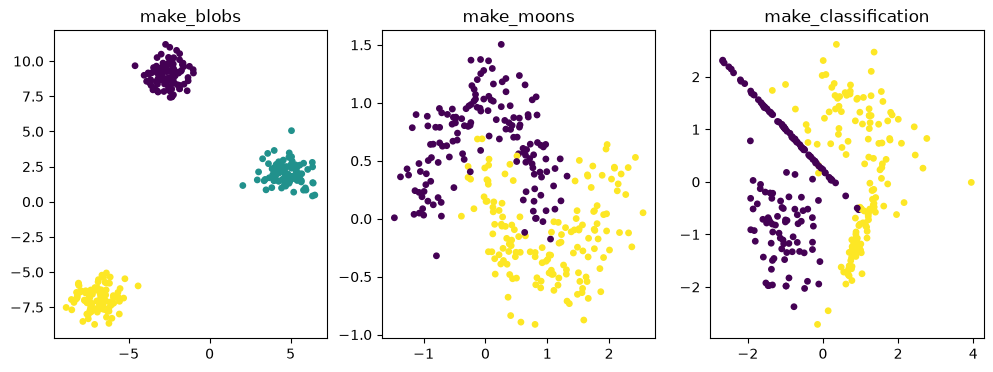

In [14]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons, make_classification

X1, y1 = make_blobs(n_samples=300, centers=3, cluster_std=0.8, random_state=42)   # 3 nuvole
X2, y2 = make_moons(n_samples=300, noise=0.2, random_state=42)                    # 2 mezzelune
X3, y3 = make_classification(n_samples=300, n_features=2, n_informative=2,
                             n_redundant=0, random_state=42)                      # 2 classi generiche

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (X, y, titolo) in zip(axes, [(X1, y1, "make_blobs"),
                                     (X2, y2, "make_moons"),
                                     (X3, y3, "make_classification")]):
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", s=15)   # colore = classe
    ax.set_title(titolo)
plt.show()

- Ogni funzione `make_*` restituisce direttamente `X, y`.
- `X[:, 0]` e `X[:, 1]` sono la prima e la seconda colonna: le usiamo come assi x e y del grafico.
- `noise` e `cluster_std` regolano quanto i gruppi sono "sporchi" e sovrapposti: più alti → problema più difficile.

## Esercizi

### Facile
Obiettivo: carica `load_breast_cancer()` e stampa numero di campioni, numero di feature, i nomi delle due classi e i nomi delle prime 5 feature.

In [ ]:
from sklearn.datasets import load_breast_cancer  # importiamo il dataset

dataset = load_breast_cancer()  # carichiamo il dataset

X = dataset.data  # contiene le feature
y = dataset.target  # contiene il target

print(X.shape[0]) # stampa numero di campioni
print(X.shape[1]) # stampa numero di feature
print(dataset.feature_names[:5]) # nomi delle 5 prime feature
print(dataset.target_names)  # stampa i nomi delle due classi

### Medio
Obiettivo: carica `load_digits()`, stampa la forma di X, visualizza le prime 10 immagini con `plt.imshow(digits.images[i], cmap="gray")` con la cifra corretta come titolo, e crea un grafico a barre con il numero di campioni per ciascuna cifra.

Forma di X: (1797, 64)


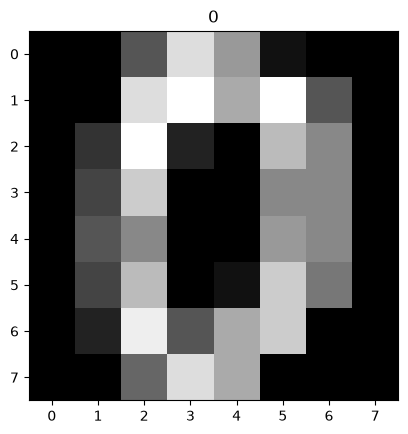

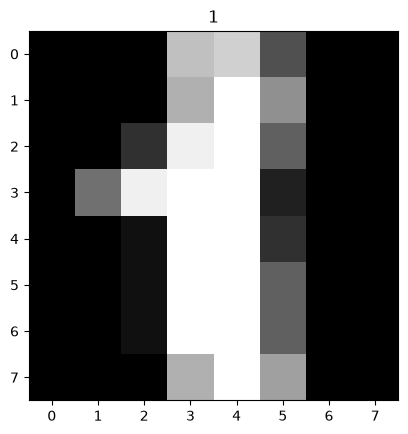

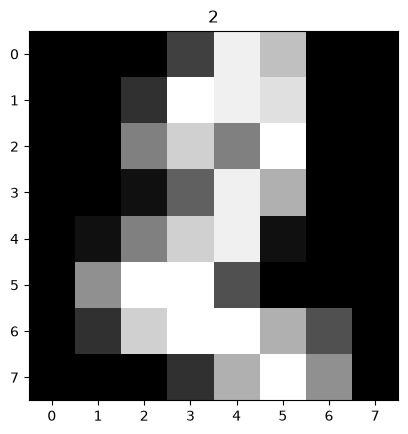

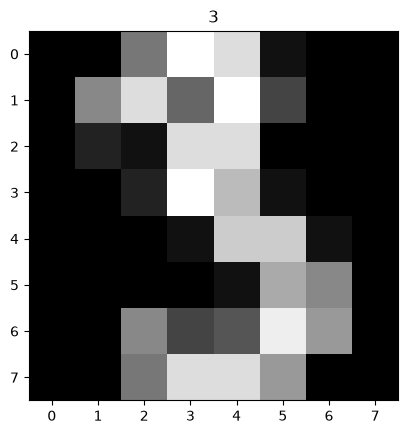

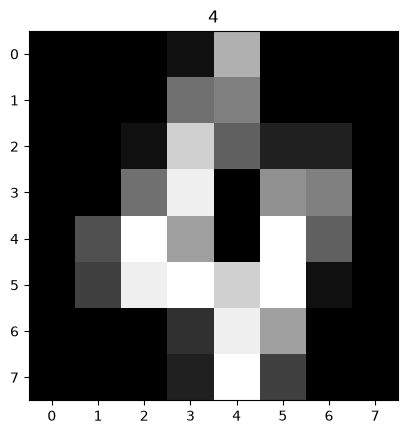

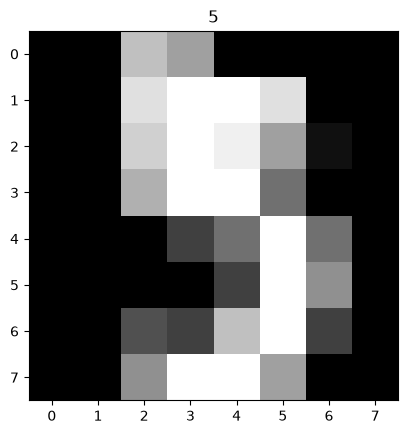

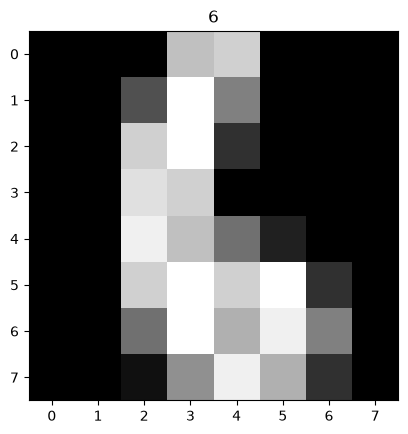

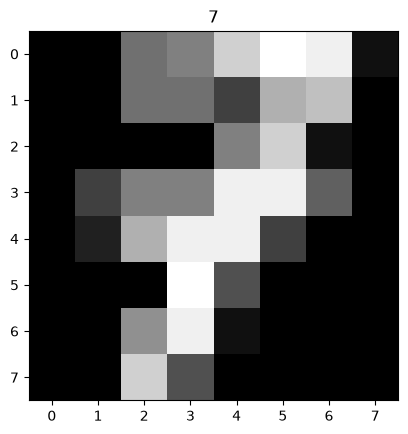

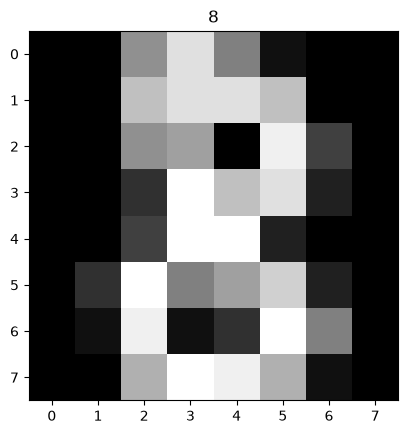

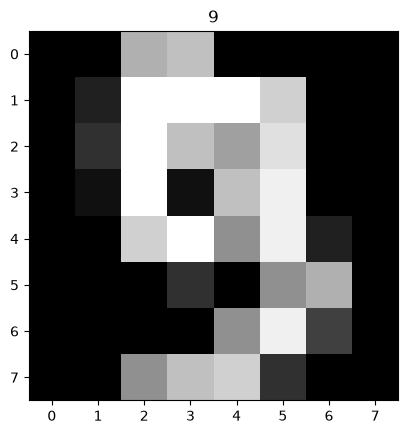

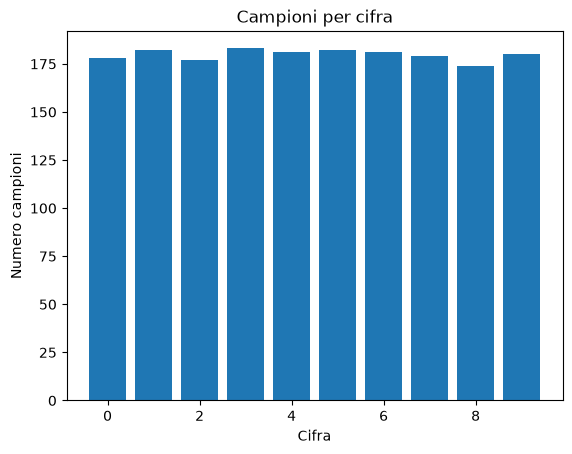

In [173]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits # importiamo il dataset

dataset = load_digits()

X = dataset.data
y = dataset.target

print('Forma di X:', X.shape)

#visualizziamo le prime 10 img

for i in range(10):
    
    plt.imshow(dataset.images[i], cmap="gray") 
    plt.title(y[i])  # inseriamo la cifra corretta
    plt.show()  # mostriamo il grafico

#creiamo un grafico a barre
    
conteggi = []  # lista dei conteggi

for i in range(10):
    totale = (y == i).sum()  # contiamo le immagini della cifra
    conteggi.append(totale)  # salviamo il totale

plt.bar(range(10), conteggi) # asse X - asse Y
plt.xlabel("Cifra")
plt.ylabel("Numero campioni")
plt.title("Campioni per cifra")
plt.show()

### Difficile
Obiettivo: genera con `make_classification` tre dataset di 300 campioni e 2 feature variando `class_sep` (0.5, 1.0, 2.0) con lo stesso `random_state`. Disegnali affiancati e descrivi come cambia la difficoltà del problema. Poi verifica che, cambiando il `random_state`, i punti cambiano mentre rieseguendo con lo stesso valore restano identici.

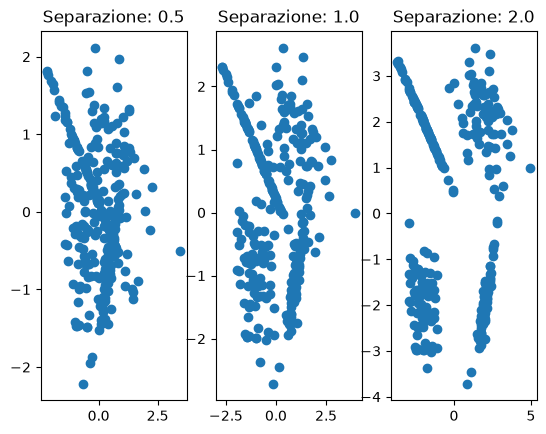

In [212]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification

# CREAZIONE DEI 3 DATASET

separazioni = [0.5, 1.0, 2.0]

for i in range(3):

    X, y = make_classification(
        n_samples=300,
        n_features=2,
        n_informative=2,
        n_redundant=0,
        class_sep=separazioni[i],
        random_state=42
    )

    plt.subplot(1, 3, i + 1)  # 3 grafici affiancati
    plt.scatter(X[:, 0], X[:, 1])  # mostriamo le due classi
    plt.title(f"Separazione: {separazioni[i]}")

plt.show()


# VERIFICA RANDOM_STATE

X1, y1 = make_classification(n_samples=300, n_features=2,
                             n_informative=2, n_redundant=0,
                             random_state=42)

X2, y2 = make_classification(n_samples=300, n_features=2,
                             n_informative=2, n_redundant=0,
                             random_state=42)

X3, y3 = make_classification(n_samples=300, n_features=2,
                             n_informative=2, n_redundant=0,
                             random_state=10)



# 1.5 L'API di scikit-learn e il workflow del Machine Learning

## Spiegazione teorica

**Estimator:** in scikit-learn ogni algoritmo è una **classe** Python. Un *modello* è un **oggetto** (istanza) di quella classe.

**Tutti i modelli si usano allo stesso modo (API uniforme)**
1. **Import** della classe: `from sklearn.neighbors import KNeighborsClassifier`
2. **Istanza** con gli iperparametri: `modello = KNeighborsClassifier(n_neighbors=3)`
3. **Addestramento:** `modello.fit(X_train, y_train)` → il modello impara dai dati.
4. **Predizione:** `modello.predict(X_nuovi)` → restituisce le risposte previste.
5. **Valutazione:** `modello.score(X_test, y_test)` → un punteggio (per i classificatori è l'accuratezza).

Grazie a questa uniformità, cambiare algoritmo significa cambiare **una sola riga** (quella dell'istanza).

**Iperparametri vs parametri** (prima definizione, approfondita il giorno 4)
- **Iperparametri:** le "manopole" che **scegliamo noi** prima dell'addestramento e passiamo tra parentesi (es. `n_neighbors=3`).
- **Parametri appresi:** i valori che il modello **calcola da solo** durante `fit`. In scikit-learn sono attributi che finiscono con underscore: `classes_`, `coef_`, `n_features_in_`… Esistono solo dopo `fit`.

**Divisione training/test: `train_test_split`**
- Per sapere se un modello funziona su dati nuovi, teniamo da parte una porzione di dati (**test set**) che il modello non vede durante l'addestramento.
- `X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)`
  - restituisce **4 oggetti in quest'ordine preciso**;
  - `test_size=0.2` → 20% dei campioni al test, 80% al training (default 0.25);
  - mescola le righe prima di dividere (`shuffle=True` di default), perché i dataset sono spesso ordinati per classe;
  - `random_state` → la stessa divisione a ogni esecuzione.

**Accuratezza (accuracy)**
- Accuratezza = previsioni corrette / previsioni totali. Va da 0 (tutto sbagliato) a 1 (tutto giusto).
- `accuracy_score(y_vero, y_previsto)` e `modello.score(X_test, y_test)` danno lo stesso valore per i classificatori.
- Limite: con classi sbilanciate può ingannare (lo approfondiamo il giorno 2).

**Il workflow tipico di un progetto ML**
1. Caricare e **esplorare** i dati.
2. **Preprocessare** (pulire, scalare, codificare) — giorno 2.
3. **Dividere** in training e test.
4. **Scegliere** un modello adatto al problema (classificazione, regressione, clustering).
5. **Addestrare** con `fit`.
6. **Predire** con `predict`.
7. **Valutare** con una metrica adatta.
8. **Ottimizzare** gli iperparametri (giorno 4) e infine **usare** il modello su dati reali.

![Scikit-learn fit](../img/sklearn-fit_FEATURED-IMAGE.png)


## Esempi teorici di utilizzo

- **Prototipazione rapida:** un analista prova 5 algoritmi diversi in 10 minuti cambiando solo la riga dell'istanza, grazie all'API uniforme.
- **Test set come esame finale:** come uno studente valutato su domande che non ha mai visto, il modello va giudicato su dati non usati nell'addestramento.
- **Riproducibilità:** in un team, fissare `random_state` garantisce che "accuratezza 0.93" significhi la stessa cosa per tutti.
- **Messa in produzione:** il modello addestrato viene salvato e poi riceve ogni giorno nuovi campioni da classificare con `predict`.

## Esempi di codice

### Base
Cosa mostra: il ciclo fit/predict su un mini dataset scritto a mano.

In [213]:
from sklearn.neighbors import KNeighborsClassifier

# Ogni riga: [peso in grammi, diametro in cm]
X = [[150, 7.0], [170, 7.5], [140, 6.8], [130, 8.5], [120, 8.8], [110, 9.0]]
y = ["mela", "mela", "mela", "arancia", "arancia", "arancia"]

modello = KNeighborsClassifier(n_neighbors=3)   # 1) istanza con iperparametro
modello.fit(X, y)                               # 2) addestramento

print(modello.predict([[160, 7.2], [115, 8.9]]))   # 3) predizione -> ['mela' 'arancia']
print(modello.classes_)                            # parametro appreso: le classi viste nel fit

['mela' 'arancia']
['arancia' 'mela']


- X è una lista di liste: ogni lista interna è un campione con 2 feature.
- Le etichette possono anche essere stringhe: scikit-learn le gestisce.
- `classes_` finisce con `_`: è stato calcolato da `fit`.

### Intermedio
Cosa mostra: il workflow completo su un dataset vero, con divisione training/test e valutazione.

In [214]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X, y = load_iris(return_X_y=True)                                   # 1) dati

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)                           # 3) divisione 80/20

modello = KNeighborsClassifier(n_neighbors=3)                       # 4) scelta del modello
modello.fit(X_train, y_train)                                       # 5) addestramento SOLO sul training
y_pred = modello.predict(X_test)                                    # 6) predizione sul test

print("accuracy_score:", accuracy_score(y_test, y_pred))            # 7) valutazione
print("score:         ", modello.score(X_test, y_test))             # stesso valore
print(X_train.shape, X_test.shape)                                  # (120, 4) (30, 4)

accuracy_score: 1.0
score:          1.0
(120, 4) (30, 4)


- L'ordine dei 4 valori restituiti da `train_test_split` è fisso: X_train, X_test, y_train, y_test.
- Il test set non partecipa al `fit`: è il nostro "esame" su dati mai visti.
- `accuracy_score` confronta verità e previsioni; `score` fa predict + confronto in un colpo.

### Avanzato
Cosa mostra: l'API uniforme permette di confrontare più algoritmi con lo stesso codice.

In [215]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

X, y = load_wine(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

modelli = {                                         # tre algoritmi diversi (li studieremo nei prossimi giorni)
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Albero": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
}

for nome, modello in modelli.items():
    modello.fit(X_train, y_train)                   # stessa chiamata per tutti
    print(f"{nome:15s} accuratezza test: {modello.score(X_test, y_test):.2f}")

KNN             accuratezza test: 0.72
Albero          accuratezza test: 0.94
Random Forest   accuratezza test: 1.00


- Il ciclo funziona solo perché tutti i modelli hanno `fit` e `score` con la stessa firma.
- KNN ottiene un risultato peggiore degli alberi: su Wine le feature hanno scale molto diverse e KNN, che usa le distanze, ne soffre (lo risolveremo con lo scaling il giorno 2).
- `random_state` nei modelli serve perché anche alcuni algoritmi usano numeri casuali.

## Esercizi

### Facile
Obiettivo: crea un mini dataset di 8 animali con feature `[peso_kg, altezza_cm]` ed etichetta "cane" o "gatto", addestra un `KNeighborsClassifier(n_neighbors=3)` e predici la classe di due animali nuovi a tua scelta.

In [216]:
# Scrivi qui la tua soluzione


### Medio
Obiettivo: su `load_breast_cancer()` esegui il workflow completo con `test_size=0.25` e `random_state=0`: addestra un KNN, calcola l'accuratezza sia con `accuracy_score` sia con `score` e verifica che coincidano. Stampa anche `n_features_in_` e `classes_`.

In [217]:
# Scrivi qui la tua soluzione


### Difficile
Obiettivo: su `load_digits()` confronta `KNeighborsClassifier`, `DecisionTreeClassifier` e `RandomForestClassifier` con un ciclo. Poi ripeti il confronto con tre valori diversi di `random_state` nello split e stampa una tabella (DataFrame pandas) con modello × random_state. La classifica dei modelli cambia?

In [218]:
# Scrivi qui la tua soluzione


# 1.6 K-Nearest Neighbors (KNN)

## Spiegazione teorica

**Idea:** "dimmi chi sono i tuoi vicini e ti dirò chi sei". Un nuovo campione riceve la classe più comune tra i campioni di training **più simili** a lui.

**Come classifica un nuovo punto**
1. Calcola la **distanza** tra il nuovo punto e **tutti** i punti del training set.
2. Seleziona i **k** punti più vicini (k = `n_neighbors`).
3. Assegna la classe più frequente tra i k vicini (**voto di maggioranza**).

**Distanza euclidea:** la distanza "in linea retta" tra due punti, il teorema di Pitagora esteso a più dimensioni.
- Due feature: `d = √((x₁ − x₂)² + (y₁ − y₂)²)`
- Esempio: A = (1, 2), B = (4, 6) → `d = √(3² + 4²) = √25 = 5`
- Con n feature si sommano n differenze al quadrato. In scikit-learn è la metrica di default (`metric="minkowski"` con `p=2`).

**Lazy learning (apprendimento pigro)**
- `fit` non costruisce nessuna formula: **memorizza** il training set.
- Tutto il lavoro avviene in `predict`, quando calcola le distanze → addestramento istantaneo, predizioni lente su dataset molto grandi.

**Scegliere k**
- k piccolo (es. 1): il modello segue ogni singolo punto, anche quelli "anomali" → sensibile al rumore (**overfitting**, alta varianza).
- k grande: il modello guarda zone molto ampie e appiattisce le differenze → troppo semplice (**underfitting**, alto bias).
- Per problemi binari si preferisce k dispari, per evitare pareggi nel voto. Il default è 5.

**Altri iperparametri e metodi utili**
- `weights="uniform"` (default): ogni vicino vale un voto. `weights="distance"`: i vicini più vicini pesano di più.
- `modello.kneighbors(X_nuovi)`: restituisce distanze e indici dei k vicini → utile per "vedere" il ragionamento del modello.
- `modello.predict_proba(X_nuovi)`: la frazione di vicini di ciascuna classe (es. 2 su 3 → 0.67).
- `KNeighborsRegressor`: versione per la regressione, prevede la **media** dei valori dei k vicini.

**Attenzione alla scala delle feature:** se una feature va da 0 a 1000 e un'altra da 0 a 1, la distanza è dominata dalla prima. Per KNN lo scaling (giorno 2) è quasi sempre necessario.

**Regione di decisione:** l'area del piano in cui il modello prevede una certa classe; il **confine di decisione** è la linea che separa le regioni.

![Scikit-learn knn](../img/knn.png)

## Esempi teorici di utilizzo

- **Sistemi di raccomandazione semplici:** "clienti simili a te hanno comprato…" è esattamente una ricerca dei vicini più prossimi.
- **Classificazione di piccoli dataset** dove la similarità ha un significato chiaro (misure fisiche, profili clinici).
- **Baseline:** essendo semplice e senza ipotesi sui dati, KNN è un ottimo primo modello con cui confrontare quelli più complessi.
- **Quando evitarlo:** dataset con milioni di righe (predizioni lente) o con moltissime feature (in tanti dimensioni "tutti i punti sono lontani" e la distanza perde significato).

## Esempi di codice

### Base
Cosa mostra: classificare un fiore nuovo e vedere quali vicini hanno deciso la classe.

In [219]:
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier

iris = load_iris()
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(iris.data, iris.target)                     # memorizza i 150 fiori

nuovo = [[6.0, 2.8, 4.9, 1.6]]                      # misure di un fiore mai visto
distanze, indici = knn.kneighbors(nuovo)            # chi sono i 3 vicini?

print("Distanze:", distanze.round(2))
print("Classi dei vicini:", iris.target[indici])    # le loro specie
print("Predizione:", iris.target_names[knn.predict(nuovo)])
print("Probabilità:", knn.predict_proba(nuovo))     # frazione di voti per classe

Distanze: [[0.22 0.3  0.3 ]]
Classi dei vicini: [[1 2 2]]
Predizione: ['virginica']
Probabilità: [[0.         0.33333333 0.66666667]]


- `kneighbors` rende trasparente la decisione: vediamo i 3 fiori più simili e le loro specie (qui 1 versicolor e 2 virginica).
- La predizione è la classe più frequente tra i vicini: virginica, 2 voti su 3.
- `predict_proba` mostra quanto è "unanime" il voto: `[0, 0.33, 0.67]`. Un fiore al confine tra due specie riceve un voto diviso.

### Intermedio
Cosa mostra: calcolare a mano la distanza euclidea e verificare che coincida con quella di scikit-learn.

In [220]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier

X, y = load_iris(return_X_y=True)
nuovo = np.array([6.1, 2.9, 4.6, 1.45])

distanze_manuali = np.sqrt(((X - nuovo) ** 2).sum(axis=1))   # Pitagora su tutte le righe
indici_vicini = np.argsort(distanze_manuali)[:5]            # indici delle 5 distanze minori
print("Vicini (manuale):", indici_vicini, distanze_manuali[indici_vicini].round(3))

knn = KNeighborsClassifier(n_neighbors=5).fit(X, y)
dist, ind = knn.kneighbors([nuovo])
print("Vicini (sklearn):", ind[0], dist[0].round(3))         # stessi punti, stesse distanze

Vicini (manuale): [91 63 78 73 97] [0.112 0.112 0.15  0.287 0.35 ]
Vicini (sklearn): [91 63 78 73 97] [0.112 0.112 0.15  0.287 0.35 ]


- `X - nuovo` sottrae il nuovo punto da ogni riga (broadcasting di NumPy).
- `argsort` restituisce gli indici che ordinerebbero l'array: i primi 5 sono i vicini.
- Il risultato coincide con `kneighbors`: KNN è davvero solo "calcola distanze e ordina".

### Avanzato
Cosa mostra: come cambia la regione di decisione con k piccolo e k grande.

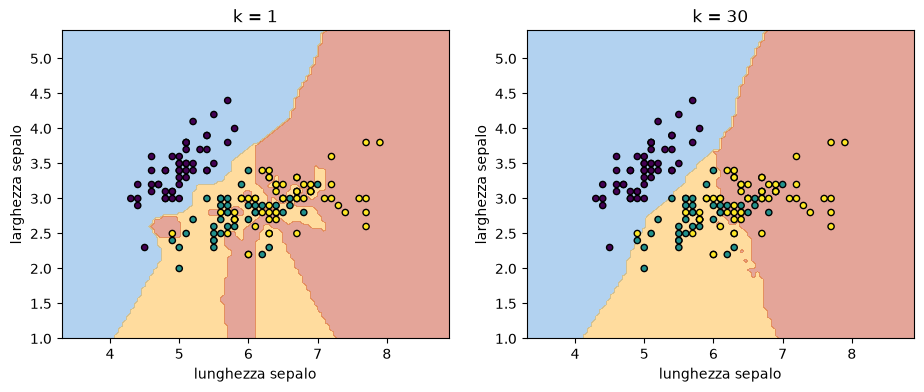

In [221]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay

X, y = load_iris(return_X_y=True)
X2 = X[:, [0, 1]]                                   # solo 2 feature per poter disegnare sul piano

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, k in zip(axes, [1, 30]):
    knn = KNeighborsClassifier(n_neighbors=k).fit(X2, y)
    DecisionBoundaryDisplay.from_estimator(          # colora il piano con la classe prevista
        knn, X2, response_method="predict", alpha=0.4, ax=ax)
    ax.scatter(X2[:, 0], X2[:, 1], c=y, edgecolor="k", s=20)
    ax.set_title(f"k = {k}")
    ax.set_xlabel("lunghezza sepalo"); ax.set_ylabel("larghezza sepalo")
plt.show()

- Con k = 1 il confine è frastagliato e crea "isole" attorno a singoli punti: il modello insegue il rumore.
- Con k = 30 il confine è molto più liscio: il modello è più stabile ma può perdere dettagli.
- `DecisionBoundaryDisplay` prova il modello su una griglia di punti e colora ciascuno con la classe prevista.

## Esercizi

### Facile
Obiettivo: su `load_wine()` addestra un `KNeighborsClassifier(n_neighbors=3)` su tutto il dataset, poi per il campione di indice 100 stampa i 3 vicini (indici, distanze, classi) con `kneighbors` e la predizione finale.

In [222]:
# Scrivi qui la tua soluzione


### Medio
Obiettivo: calcola a mano (con NumPy) la distanza euclidea tra il primo e il secondo campione di `load_wine()` e verifica il risultato con `np.linalg.norm`. Poi identifica quale feature contribuisce di più alla distanza e spiega perché questo è un problema per KNN.

In [223]:
# Scrivi qui la tua soluzione


### Difficile
Obiettivo: su `load_diabetes()` (regressione) usa `KNeighborsRegressor` con k = 1, 5, 20 e con `weights` "uniform" e "distance". Dividi i dati 80/20 e stampa `score` sul test per tutte e 6 le combinazioni (lo `score` di un regressore vale 1 se perfetto, si abbassa al peggiorare e può diventare negativo). Quale combinazione funziona meglio?

In [224]:
# Scrivi qui la tua soluzione


# 1.7 Generalizzazione: training, validation, test, overfitting e underfitting

## Spiegazione teorica

**Generalizzazione:** la capacità di un modello di funzionare bene su dati **nuovi**. È l'unica cosa che conta davvero: un modello che va bene solo sui dati di addestramento è inutile.

**Errore di training vs errore di test**
- Errore di training: quanto sbaglia sui dati che ha usato per imparare (troppo ottimista).
- Errore di test: quanto sbaglia su dati mai visti (stima realistica).
- Valutare un modello sugli stessi dati usati per addestrarlo è come dare agli studenti l'esame con le stesse domande dell'esercitazione: il voto non misura cosa hanno capito.

**Overfitting (sovradattamento)**
- Il modello impara **troppo bene** i dati di training, compresi rumore ed eccezioni: li "memorizza".
- Sintomo: punteggio di training molto alto, punteggio di test nettamente più basso.
- Cause tipiche: modello troppo complesso (es. KNN con k = 1), pochi dati.

**Underfitting (sottoadattamento)**
- Il modello è **troppo semplice** per cogliere la struttura dei dati.
- Sintomo: punteggi bassi **sia** sul training **sia** sul test.
- Cause tipiche: modello troppo rigido (es. KNN con k enorme), feature poco informative.

**Bias e varianza (intuizione)**
- **Bias** alto = il modello fa ipotesi troppo semplici → sbaglia sistematicamente (underfitting).
- **Varianza** alta = il modello cambia molto se cambiano un po' i dati di training → instabile (overfitting).
- L'obiettivo è il punto di equilibrio: il "giusto mezzo" di complessità.

**Tre insiemi di dati**
- **Training set:** per addestrare (`fit`).
- **Validation set:** per **scegliere** gli iperparametri (es. il miglior k) confrontando più versioni del modello.
- **Test set:** usato **una sola volta alla fine**, per stimare le prestazioni del modello scelto.
- Perché non scegliere k direttamente sul test? Perché provando molti k e tenendo il migliore sul test, il test diventa parte della scelta e la stima finale risulta ottimista.
- Proporzioni tipiche: 60/20/20 o 70/15/15. Con pochi dati si usa la **validazione incrociata** (cross-validation, giorno 4).

## Esempi teorici di utilizzo

- **Modello di credito:** il 100% di accuratezza sui clienti passati e il 60% sui nuovi è overfitting: la banca deve basarsi sulla stima di test.
- **Scelta della complessità:** si confrontano versioni più semplici e più complesse dello stesso modello sul validation set e si sceglie quella che generalizza meglio, non quella che va meglio sul training.
- **Rapporto per il cliente:** il numero da comunicare è quello del test set, mai quello del training.
- **Diagnosi rapida:** training alto + test basso → semplificare il modello o raccogliere più dati; entrambi bassi → modello più potente o feature migliori.

## Esempi di codice

### Base
Cosa mostra: il sintomo dell'overfitting: training perfetto, test peggiore.

In [225]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

X, y = make_moons(n_samples=400, noise=0.35, random_state=42)    # dati con molto rumore
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

for k in [1, 15]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    print(f"k={k:2d}  training: {knn.score(X_train, y_train):.2f}"   # punteggio sui dati visti
          f"  test: {knn.score(X_test, y_test):.2f}")                # punteggio su dati nuovi

k= 1  training: 1.00  test: 0.83
k=15  training: 0.87  test: 0.89


- Con k = 1 l'accuratezza di training è 1.00: ogni punto è il vicino di sé stesso, il modello ha memorizzato.
- Il test con k = 1 è più basso: la memorizzazione non si trasferisce ai dati nuovi.
- Con k = 15 training e test sono più vicini tra loro: il modello generalizza meglio.

### Intermedio
Cosa mostra: dividere in training/validation/test e scegliere k senza "sbirciare" il test.

In [226]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

X, y = load_breast_cancer(return_X_y=True)

# 1° split: 80% (train+validation) / 20% test
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# 2° split: dal restante 80%, il 25% va in validation -> 60/20/20 sul totale
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

migliore_k, migliore_val = None, 0
for k in range(1, 31, 2):                                   # k dispari da 1 a 29
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    val = knn.score(X_val, y_val)                           # la scelta si fa sul VALIDATION
    if val > migliore_val:
        migliore_k, migliore_val = k, val

finale = KNeighborsClassifier(n_neighbors=migliore_k).fit(X_train, y_train)
print("k scelto:", migliore_k, "| validation:", round(migliore_val, 3))
print("Stima finale sul test:", round(finale.score(X_test, y_test), 3))   # test usato UNA volta

k scelto: 3 | validation: 0.939
Stima finale sul test: 0.947


- Due chiamate a `train_test_split` producono tre insiemi.
- Il test set compare solo nell'ultima riga: non ha influenzato la scelta di k.
- La stima sul test è il numero "onesto" da comunicare.

### Avanzato
Cosa mostra: la curva di complessità, che rende visibili overfitting e underfitting.

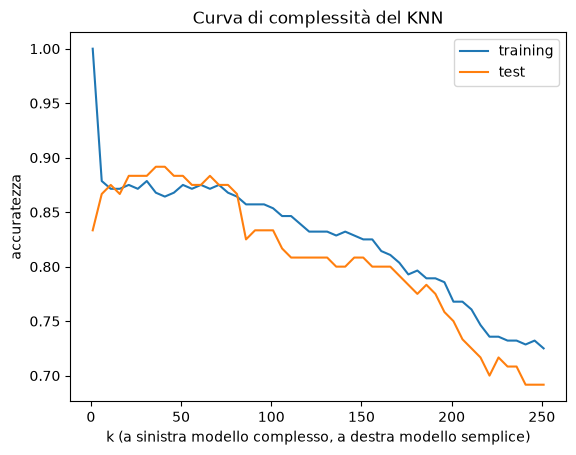

In [227]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

X, y = make_moons(n_samples=400, noise=0.35, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

valori_k = range(1, 252, 5)                         # da 1 fino a quasi tutto il training (280 punti)
acc_train, acc_test = [], []
for k in valori_k:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    acc_train.append(knn.score(X_train, y_train))
    acc_test.append(knn.score(X_test, y_test))

plt.plot(valori_k, acc_train, label="training")
plt.plot(valori_k, acc_test, label="test")
plt.xlabel("k (a sinistra modello complesso, a destra modello semplice)")
plt.ylabel("accuratezza")
plt.legend(); plt.title("Curva di complessità del KNN")
plt.show()

- A sinistra (k piccolo) training altissimo e test più basso: zona di **overfitting**.
- A destra (k molto grande) entrambe le curve scendono: ogni previsione è una media su quasi tutti i punti, zona di **underfitting**.
- Il k migliore è nella zona centrale, dove la curva di test è più alta.

## Esercizi

### Facile
Obiettivo: su `load_digits()` addestra un KNN con k = 1 e calcola l'accuratezza su training e test (split 75/25). Il modello è in overfitting? Motiva guardando i due numeri.

In [228]:
# Scrivi qui la tua soluzione


### Medio
Obiettivo: su `make_circles(n_samples=500, noise=0.25, factor=0.5, random_state=0)` crea una divisione 60/20/20 in training/validation/test, scegli il miglior k tra 1 e 50 sul validation set e riporta l'accuratezza finale sul test.

In [229]:
# Scrivi qui la tua soluzione


### Difficile
Obiettivo: su `load_wine()` disegna la curva di accuratezza training/test al variare di k (da 1 a 60). Poi ripeti lo split con 5 valori diversi di `random_state` e disegna le 5 curve di test sullo stesso grafico: quanto cambia la stima? Scrivi tre righe su cosa implica questo per l'affidabilità di un singolo split (anticipazione della cross-validation).

In [230]:
# Scrivi qui la tua soluzione
